In [4]:
import pandas as pd

# 1. 데이터 로드 (notebooks 폴더 상위인 ../data/raw/ 경로 지정)
file_path = '../data/raw/diabetes_binary_health_indicators_BRFSS2015.csv'
df = pd.read_csv(file_path)

# 만약 processed 폴더의 정제된 데이터를 쓰고 싶다면 아래 주석을 해제해 사용하세요
# df = pd.read_csv('../data/processed/diabetes_binary_health_indicators_cleaned.csv')

# 2. 각 컬럼의 고유값 개수와 범위를 검사하여 유형 분류
summary = []
for col in df.columns:
    n_unique = df[col].nunique()
    min_val = df[col].min()
    max_val = df[col].max()
    
    if n_unique <= 2:
        var_type = '이진형 (Binary)'
    elif n_unique <= 15:
        var_type = '등급/순서형 (Ordinal)'
    else:
        var_type = '연속형 수치 (Continuous)'
        
    summary.append({
        '지표명': col,
        '고유값 개수': n_unique,
        '값 범위': f"{int(min_val)} ~ {int(max_val)}",
        '분류 결과': var_type
    })

result_df = pd.DataFrame(summary)

# 3. 전체 분류 결과표 출력
print("=== [1] 전체 22개 지표 유형 자동 분류 결과 ===")
print(result_df.to_string(index=False))

# 4. 연속형 수치 변수만 추출하여 최종 결론 도출
continuous_cols = result_df[result_df['분류 결과'] == '연속형 수치 (Continuous)']['지표명'].tolist()
categorical_cols = result_df[result_df['분류 결과'] != '연속형 수치 (Continuous)']['지표명'].tolist()

print("\n=== [2] 최종 판별 결론 ===")
print(f"• 연속형 수치 변수 ({len(continuous_cols)}개): {continuous_cols}")
print(f"• 이진 및 등급화 변수 ({len(categorical_cols)}개): {categorical_cols}")

# 검증(Assertion)
assert continuous_cols == ['BMI', 'MentHlth', 'PhysHlth'], "분류 기준을 다시 확인해주세요."
print("-> 검증 완료: 전체 22개 지표 중 ['BMI', 'MentHlth', 'PhysHlth'] 3개만 연속형 수치 자료입니다.")

=== [1] 전체 22개 지표 유형 자동 분류 결과 ===
                 지표명  고유값 개수    값 범위               분류 결과
     Diabetes_binary       2   0 ~ 1        이진형 (Binary)
              HighBP       2   0 ~ 1        이진형 (Binary)
            HighChol       2   0 ~ 1        이진형 (Binary)
           CholCheck       2   0 ~ 1        이진형 (Binary)
                 BMI      84 12 ~ 98 연속형 수치 (Continuous)
              Smoker       2   0 ~ 1        이진형 (Binary)
              Stroke       2   0 ~ 1        이진형 (Binary)
HeartDiseaseorAttack       2   0 ~ 1        이진형 (Binary)
        PhysActivity       2   0 ~ 1        이진형 (Binary)
              Fruits       2   0 ~ 1        이진형 (Binary)
             Veggies       2   0 ~ 1        이진형 (Binary)
   HvyAlcoholConsump       2   0 ~ 1        이진형 (Binary)
       AnyHealthcare       2   0 ~ 1        이진형 (Binary)
         NoDocbcCost       2   0 ~ 1        이진형 (Binary)
             GenHlth       5   1 ~ 5    등급/순서형 (Ordinal)
            MentHlth      31  0 ~ 30 연속형 수치 (Continuou

## [지표별 수치 구별] 연속수치 3개: BMI', 'MentHlth', 'PhysHlth'

 등급변수4개: GenHlth       5, Age      13, Education       6, Income       8  

 이진변수 15개



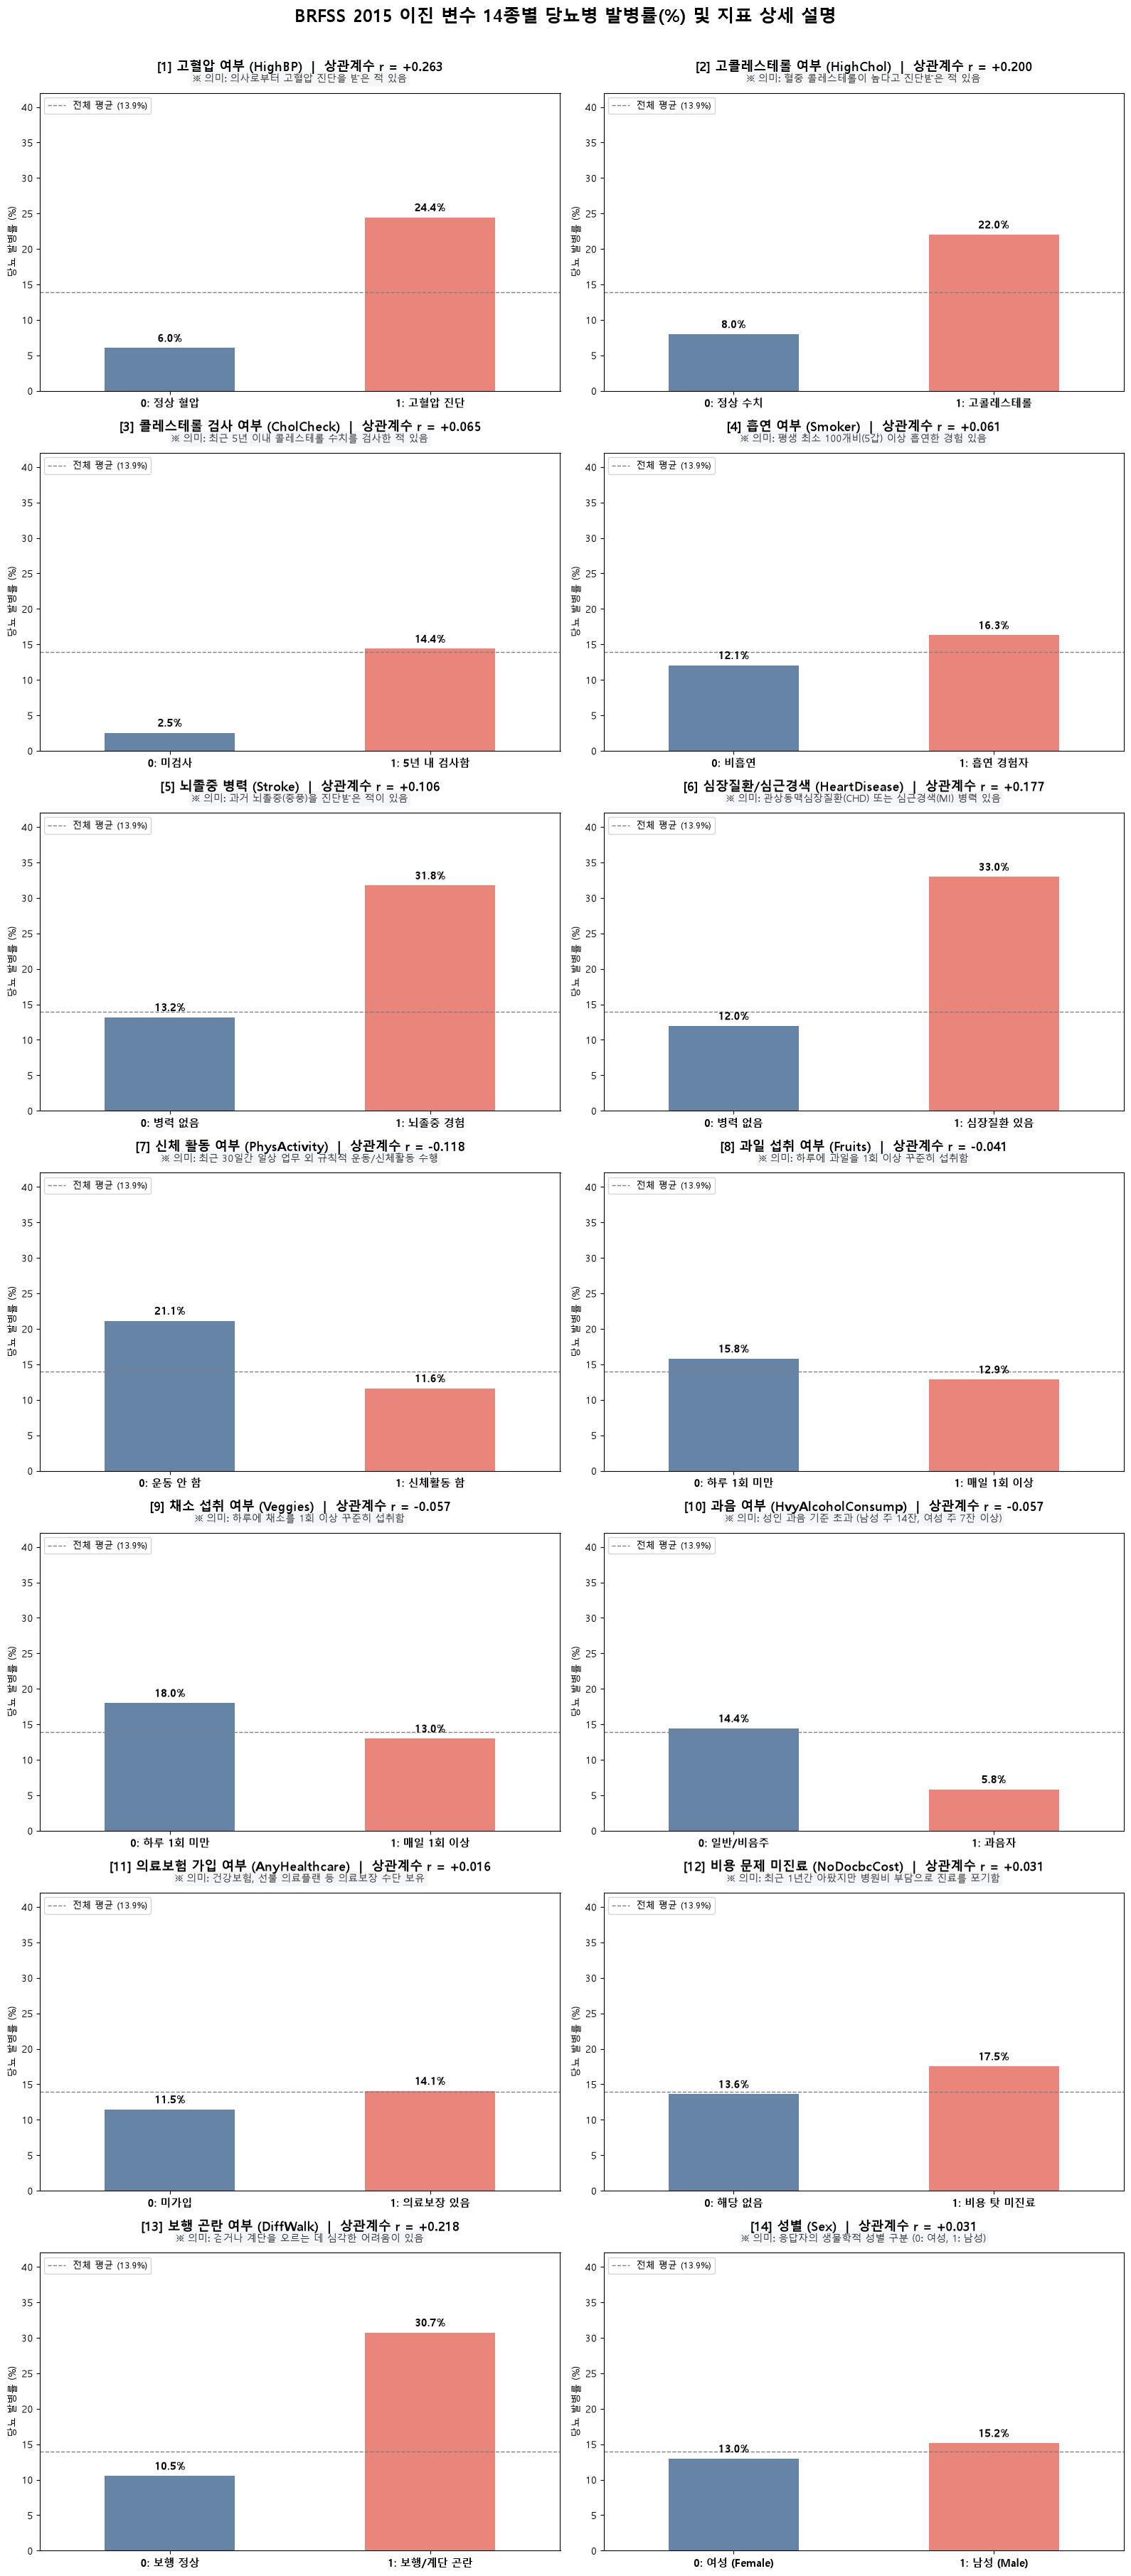

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 한글 폰트 및 마이너스 기호 깨짐 방지 (Windows 기준)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 2. 데이터 로드 (notebooks/ 폴더 기준 상위 경로 지정)
file_path = '../data/raw/diabetes_binary_health_indicators_BRFSS2015.csv'
df = pd.read_csv(file_path)

# 3. 타겟(Diabetes_binary)을 제외한 14개 이진 변수 및 상세 의미 정의 (BRFSS 2015 기준)
binary_info = {
    'HighBP': {
        'title': '고혈압 여부 (HighBP)',
        'desc': '의사로부터 고혈압 진단을 받은 적 있음',
        'labels': ['0: 정상 혈압', '1: 고혈압 진단']
    },
    'HighChol': {
        'title': '고콜레스테롤 여부 (HighChol)',
        'desc': '혈중 콜레스테롤이 높다고 진단받은 적 있음',
        'labels': ['0: 정상 수치', '1: 고콜레스테롤']
    },
    'CholCheck': {
        'title': '콜레스테롤 검사 여부 (CholCheck)',
        'desc': '최근 5년 이내 콜레스테롤 수치를 검사한 적 있음',
        'labels': ['0: 미검사', '1: 5년 내 검사함']
    },
    'Smoker': {
        'title': '흡연 여부 (Smoker)',
        'desc': '평생 최소 100개비(5갑) 이상 흡연한 경험 있음',
        'labels': ['0: 비흡연', '1: 흡연 경험자']
    },
    'Stroke': {
        'title': '뇌졸중 병력 (Stroke)',
        'desc': '과거 뇌졸중(중풍)을 진단받은 적이 있음',
        'labels': ['0: 병력 없음', '1: 뇌졸중 경험']
    },
    'HeartDiseaseorAttack': {
        'title': '심장질환/심근경색 (HeartDisease)',
        'desc': '관상동맥심장질환(CHD) 또는 심근경색(MI) 병력 있음',
        'labels': ['0: 병력 없음', '1: 심장질환 있음']
    },
    'PhysActivity': {
        'title': '신체 활동 여부 (PhysActivity)',
        'desc': '최근 30일간 일상 업무 외 규칙적 운동/신체활동 수행',
        'labels': ['0: 운동 안 함', '1: 신체활동 함']
    },
    'Fruits': {
        'title': '과일 섭취 여부 (Fruits)',
        'desc': '하루에 과일을 1회 이상 꾸준히 섭취함',
        'labels': ['0: 하루 1회 미만', '1: 매일 1회 이상']
    },
    'Veggies': {
        'title': '채소 섭취 여부 (Veggies)',
        'desc': '하루에 채소를 1회 이상 꾸준히 섭취함',
        'labels': ['0: 하루 1회 미만', '1: 매일 1회 이상']
    },
    'HvyAlcoholConsump': {
        'title': '과음 여부 (HvyAlcoholConsump)',
        'desc': '성인 과음 기준 초과 (남성 주 14잔, 여성 주 7잔 이상)',
        'labels': ['0: 일반/비음주', '1: 과음자']
    },
    'AnyHealthcare': {
        'title': '의료보험 가입 여부 (AnyHealthcare)',
        'desc': '건강보험, 선불 의료플랜 등 의료보장 수단 보유',
        'labels': ['0: 미가입', '1: 의료보장 있음']
    },
    'NoDocbcCost': {
        'title': '비용 문제 미진료 (NoDocbcCost)',
        'desc': '최근 1년간 아팠지만 병원비 부담으로 진료를 포기함',
        'labels': ['0: 해당 없음', '1: 비용 탓 미진료']
    },
    'DiffWalk': {
        'title': '보행 곤란 여부 (DiffWalk)',
        'desc': '걷거나 계단을 오르는 데 심각한 어려움이 있음',
        'labels': ['0: 보행 정상', '1: 보행/계단 곤란']
    },
    'Sex': {
        'title': '성별 (Sex)',
        'desc': '응답자의 생물학적 성별 구분 (0: 여성, 1: 남성)',
        'labels': ['0: 여성 (Female)', '1: 남성 (Male)']
    }
}

# 4. 7행 2열(총 14칸) 서브플롯으로 한 번에 시각화
fig, axes = plt.subplots(nrows=7, ncols=2, figsize=(16, 36))
axes = axes.flatten()

# 전체 평균 당뇨 유병률 기준선 (약 13.9%)
overall_rate = df['Diabetes_binary'].mean() * 100

for idx, (col, info) in enumerate(binary_info.items()):
    ax = axes[idx]
    
    # 그룹별 당뇨 발병률(%) 및 상관계수 계산
    prob_df = df.groupby(col)['Diabetes_binary'].mean().reset_index()
    prob_df['Diabetes_Rate'] = prob_df['Diabetes_binary'] * 100
    corr = df[col].corr(df['Diabetes_binary'])
    
    # 막대그래프 그리기
    sns.barplot(
        data=prob_df,
        x=col,
        y='Diabetes_Rate',
        hue=col,
        palette=['#5B84B1', '#FC766A'],
        legend=False,
        ax=ax,
        width=0.5
    )
    
    # 전체 평균 당뇨율 점선 추가
    ax.axhline(overall_rate, color='gray', linestyle='--', linewidth=1, label=f'전체 평균 ({overall_rate:.1f}%)')
    
    # 제목 및 변수 상세 설명 배치
    ax.set_title(f"[{idx+1}] {info['title']}  |  상관계수 r = {corr:+.3f}", fontsize=13, fontweight='bold', pad=22)
    ax.text(0.5, 1.03, f"※ 의미: {info['desc']}", transform=ax.transAxes,
            ha='center', va='bottom', fontsize=10, color='#333333',
            bbox=dict(boxstyle='round,pad=0.25', facecolor='#F4F6F8', edgecolor='none'))
    
    # 축 레이블 및 범위 설정
    ax.set_xticks([0, 1])
    ax.set_xticklabels(info['labels'], fontsize=10.5, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('당뇨 발병률 (%)', fontsize=10)
    ax.set_ylim(0, 42)
    ax.legend(loc='upper left', fontsize=9)
    
    # 막대 위에 정확한 퍼센트(%) 수치 표시
    for p in ax.patches:
        h = p.get_height()
        ax.annotate(
            f'{h:.1f}%',
            (p.get_x() + p.get_width() / 2., h),
            ha='center', va='bottom',
            fontsize=11, fontweight='bold',
            xytext=(0, 4), textcoords='offset points'
        )

plt.suptitle('BRFSS 2015 이진 변수 14종별 당뇨병 발병률(%) 및 지표 상세 설명', fontsize=18, fontweight='bold', y=1.005)
plt.tight_layout()

# 필요시 이미지 파일로 저장 (주석 해제 후 사용)
# plt.savefig('../reports/figures/binary_14_features_diabetes_relation.png', dpi=300, bbox_inches='tight')
plt.show()

## [모델링 인사이트 요약]
당뇨병 판별에는 HighBP, DiffWalk, HighChol, HeartDiseaseorAttack, PhysActivity 5가지 이진 지표가 핵심 변별력을 가지며, HvyAlcoholConsump나 CholCheck처럼 환자의 사후 행동 변화(금주, 병원 검사 증가)가 반영된 지표는 해석 시 인과관계 방향을 주의해야 함.

1. 고위험 대사·심혈관 질환 및 신체 기능 (가장 강한 양의 상관관계)해당 조건이 있을 때(1) 당뇨 발병률이 22% ~ 33%대로 급증하며, 전체 14개 변수 중 가장 뚜렷한 예측력을 보입니다.HighBP (고혈압 여부, $r = +0.263$): 고혈압 진단 시 당뇨 발병률 24.4% (정상 6.0% 대비 약 4배 급증)   DiffWalk (보행 곤란 여부, $r = +0.218$): 걷기·계단 오르기 곤란 시 30.7% (정상 10.5% 대비 약 3배)   HighChol (고콜레스테롤 여부, $r = +0.200$): 고콜레스테롤 진단 시 22.0% (정상 8.0% 대비 약 2.8배)   HeartDiseaseorAttack (심장질환/심근경색, $r = +0.177$): 병력 보유 시 33.0%로 14개 이진 변수 중 최고 발병률 기록 (없음 12.0%)   Stroke (뇌졸중 병력, $r = +0.106$): 뇌졸중 경험 시 31.8% (없음 13.2%)   

2. 보호 요인 및 생활습관 (음의 상관관계 / 예방 효과)건강한 생활습관을 실천할 때(1) 당뇨 유병률이 전체 평균(13.9%) 아래로 낮아집니다.   PhysActivity (신체 활동, $r = -0.118$): 운동 시 11.6% vs 미실천 시 21.1% (생활습관 중 가장 큰 격차)   Veggies (채소 섭취, $r = -0.057$) & Fruits (과일 섭취, $r = -0.041$): 매일 1회 이상 섭취 시 각각 13.0%, 12.8%로 비섭취군(18.0%, 15.8%)보다 낮음   HvyAlcoholConsump (과음 여부, $r = -0.057$): 과음군의 유병률(5.8%)이 비과음군(14.4%)보다 낮게 나타남 (※ 설문 조사 특성상 이미 당뇨·만성질환 진단을 받은 환자들이 금주하면서 나타나는 역인과성/생존 편향 해석 주의)   

3. 의료 접근성·인구통계 및 기타 지표 (약한 상관관계)CholCheck (5년 내 콜레스테롤 검사, $r = +0.065$): 검사군 14.4% vs 미검사군 2.2% (※ 건강 이상 증상이 있거나 정기 검진을 받는 사람일수록 당뇨를 발견할 확률이 높기 때문)   Smoker (흡연 경험, $r = +0.061$): 흡연 경험자 16.3% vs 비흡연자 12.1%   NoDocbcCost (비용 탓 미진료, $r = +0.031$): 의료비 부담 경험 시 17.5% (없음 13.6%) — 경제적 취약계층의 만성질환 위험 반영   Sex (성별, $r = +0.031$) & AnyHealthcare (의료보험, $r = +0.016$): 남성(15.2%)이 여성(13.0%)보다 소폭 높으며, 의료보험 유무(14.1% vs 11.5%)는 단독 설명력이 낮음   

## [이진변수의 경우] 핵심지표 추출

🎯 1순위: 핵심 예측 지표 (Top 6 — 모델 성능의 80% 이상을 결정)당뇨병(Diabetes_binary)과 상관계수 절댓값이 가장 높고($\vert{}r\vert{} \ge 0.17$), 유병률 격차가 2~4배 이상 벌어지는 필수 투입 변수! <HighBP(고혈압), DiffWalk(보행 어려움), HighChol(고콜레스테롤), HeartDiseaseorAttack(심장질환/심근경색), PhysActivity(신체활동 여부), Stroke(뇌졸중)>

📌 2순위: 보조 및 맥락 보완 지표 (4개 — 모델 정밀도 향상용)단독 상관도는 1순위보다 낮지만($\vert{}r\vert{} = 0.11 \sim 0.17$), 심혈관 합병증·생활습관·사회경제적 배경을 보완해 예측력을 높여줌

 1)HeartDiseaseorAttack (심장질환/심근경색, $r = +0.18$): 전체 이진 변수 중 유병률 1위(33.0%)를 기록한 초고위험 합병증 지표. 

 2)PhysHlth (신체 건강 악화 일수, $r = +0.17$): 트리 모델(Random Forest, XGBoost)에서는 유용하나, GenHlth와 상관계수가 0.52로 높으므로 로지스틱 회귀 같은 선형 모델에서는 다중공선성(규제 적용 또는 택1)을 주의해야 함 

 3)Income (소득 수준, $r = -0.16$) & Education (학력 수준, $r = -0.12$): 수치가 높을수록 당뇨 위험이 낮아지는 사회경제적 보호 요인. (단, 두 변수 간 상관계수가 0.45이므로 선형 모델에서는 하나만 쓰거나 규제를 적용)

 4)PhysActivity (신체 활동 여부, $r = -0.12$): 운동 미실천(21.1%) vs 실천(11.6%)으로 생활습관 중 가장 뚜렷한 예방 효과를 보임

## [이진변수의 경우] 모델링 추천 조합
경량·고효율 모델 (실무/서비스 배포용): 1순위 6개 지표 + HeartDiseaseorAttack, PhysActivity, Income (총 9개)만으로도 전체 21개 변수를 다 넣었을 때와 거의 동일한 예측 성능(ROC-AUC)을 낼 수 있음.
파생변수 추가 시: 위 핵심 지표들을 바탕으로 앞서 만든 Triple_Risk(고혈압+고콜레스테롤+비만)와 Bad_Lifestyle(운동부족+흡연)을 함께 투입해 중요도(Feature Importance)를 비교가능


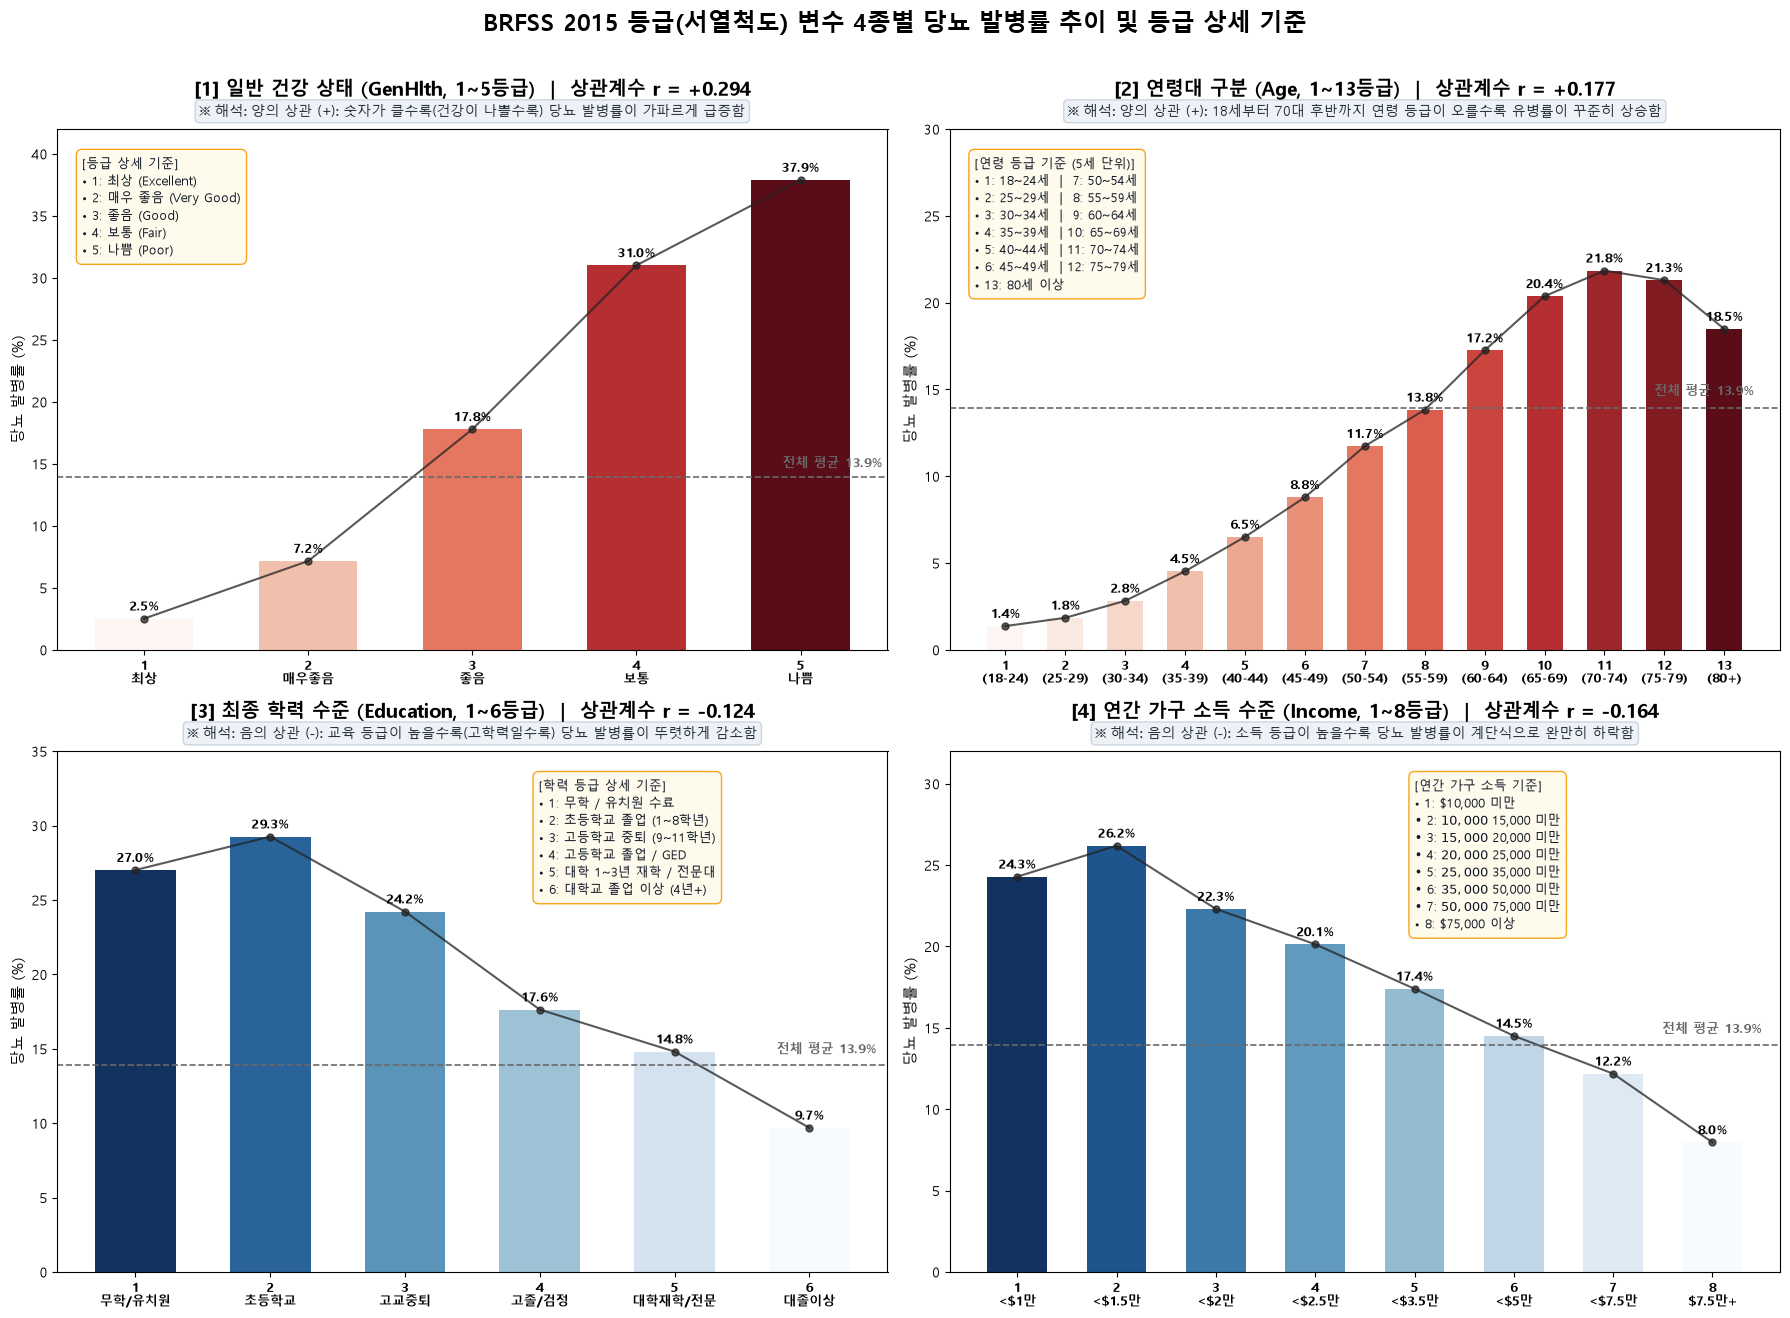

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 한글 폰트 및 마이너스 기호 깨짐 방지 (Windows 기준)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 2. 데이터 로드 (notebooks/ 폴더 기준 상위 경로 지정)
file_path = '../data/raw/diabetes_binary_health_indicators_BRFSS2015.csv'
df = pd.read_csv(file_path)

# 3. 등급 변수 4종의 상세 코드 의미 및 상관 해석 정의 (CDC BRFSS 2015 기준)
ordinal_info = {
    'GenHlth': {
        'title': '일반 건강 상태 (GenHlth, 1~5등급)',
        'corr_desc': '양의 상관 (+): 숫자가 클수록(건강이 나쁠수록) 당뇨 발병률이 가파르게 급증함',
        'xticks': ['1\n최상', '2\n매우좋음', '3\n좋음', '4\n보통', '5\n나쁨'],
        'legend_text': (
            "[등급 상세 기준]\n"
            "• 1: 최상 (Excellent)\n"
            "• 2: 매우 좋음 (Very Good)\n"
            "• 3: 좋음 (Good)\n"
            "• 4: 보통 (Fair)\n"
            "• 5: 나쁨 (Poor)"
        ),
        'box_loc': (0.03, 0.95),  # 좌측 상단 여백 배치
        'box_va': 'top',
        'ylim': 42
    },
    'Age': {
        'title': '연령대 구분 (Age, 1~13등급)',
        'corr_desc': '양의 상관 (+): 18세부터 70대 후반까지 연령 등급이 오를수록 유병률이 꾸준히 상승함',
        'xticks': [
            '1\n(18-24)', '2\n(25-29)', '3\n(30-34)', '4\n(35-39)',
            '5\n(40-44)', '6\n(45-49)', '7\n(50-54)', '8\n(55-59)',
            '9\n(60-64)', '10\n(65-69)', '11\n(70-74)', '12\n(75-79)', '13\n(80+)'
        ],
        'legend_text': (
            "[연령 등급 기준 (5세 단위)]\n"
            "• 1: 18~24세  |  7: 50~54세\n"
            "• 2: 25~29세  |  8: 55~59세\n"
            "• 3: 30~34세  |  9: 60~64세\n"
            "• 4: 35~39세  | 10: 65~69세\n"
            "• 5: 40~44세  | 11: 70~74세\n"
            "• 6: 45~49세  | 12: 75~79세\n"
            "• 13: 80세 이상"
        ),
        'box_loc': (0.03, 0.95),  # 좌측 상단 여백 배치
        'box_va': 'top',
        'ylim': 30
    },
    'Education': {
        'title': '최종 학력 수준 (Education, 1~6등급)',
        'corr_desc': '음의 상관 (-): 교육 등급이 높을수록(고학력일수록) 당뇨 발병률이 뚜렷하게 감소함',
        'xticks': [
            '1\n무학/유치원', '2\n초등학교', '3\n고교중퇴',
            '4\n고졸/검정', '5\n대학재학/전문', '6\n대졸이상'
        ],
        'legend_text': (
            "[학력 등급 상세 기준]\n"
            "• 1: 무학 / 유치원 수료\n"
            "• 2: 초등학교 졸업 (1~8학년)\n"
            "• 3: 고등학교 중퇴 (9~11학년)\n"
            "• 4: 고등학교 졸업 / GED\n"
            "• 5: 대학 1~3년 재학 / 전문대\n"
            "• 6: 대학교 졸업 이상 (4년+)"
        ),
        'box_loc': (0.58, 0.95),  # 우측 상단 여백 배치 (우하향 그래프이므로 오른쪽 위가 비어 있음)
        'box_va': 'top',
        'ylim': 35
    },
    'Income': {
        'title': '연간 가구 소득 수준 (Income, 1~8등급)',
        'corr_desc': '음의 상관 (-): 소득 등급이 높을수록 당뇨 발병률이 계단식으로 완만히 하락함',
        'xticks': [
            '1\n<$1만', '2\n<$1.5만', '3\n<$2만', '4\n<$2.5만',
            '5\n<$3.5만', '6\n<$5만', '7\n<$7.5만', '8\n$7.5만+'
        ],
        'legend_text': (
            "[연간 가구 소득 기준]\n"
            "• 1: $10,000 미만\n"
            "• 2: $10,000 ~ $15,000 미만\n"
            "• 3: $15,000 ~ $20,000 미만\n"
            "• 4: $20,000 ~ $25,000 미만\n"
            "• 5: $25,000 ~ $35,000 미만\n"
            "• 6: $35,000 ~ $50,000 미만\n"
            "• 7: $50,000 ~ $75,000 미만\n"
            "• 8: $75,000 이상"
        ),
        'box_loc': (0.56, 0.95),  # 우측 상단 여백 배치
        'box_va': 'top',
        'ylim': 32
    }
}

# 4. 2행 2열 서브플롯으로 시각화
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(18, 13))
axes = axes.flatten()

overall_rate = df['Diabetes_binary'].mean() * 100

for idx, (col, info) in enumerate(ordinal_info.items()):
    ax = axes[idx]
    
    # 등급별 당뇨 발병률(%) 및 상관계수 계산
    prob_df = df.groupby(col)['Diabetes_binary'].mean().reset_index()
    prob_df['Diabetes_Rate'] = prob_df['Diabetes_binary'] * 100
    corr = df[col].corr(df['Diabetes_binary'])
    
    # 양의 상관(+)은 붉은 계열(Reds), 음의 상관(-)은 푸른 계열(Blues_r)로 색상 직관화
    palette = 'Reds' if corr > 0 else 'Blues_r'
    
    sns.barplot(
        data=prob_df,
        x=col,
        y='Diabetes_Rate',
        hue=col,
        palette=palette,
        legend=False,
        ax=ax,
        width=0.6
    )
    
    # 추세선(꺾은선) 오버레이하여 등급 변화에 따른 흐름 강조
    ax.plot(
        range(len(prob_df)),
        prob_df['Diabetes_Rate'],
        color='#222222',
        marker='o',
        markersize=5,
        linewidth=1.5,
        alpha=0.75
    )
    
    # 전체 평균 당뇨 유병률(13.9%) 기준선
    ax.axhline(overall_rate, color='dimgray', linestyle='--', linewidth=1.2)
    ax.text(len(prob_df) - 0.5, overall_rate + 0.6, f'전체 평균 {overall_rate:.1f}%',
            ha='right', va='bottom', fontsize=9, color='dimgray', fontweight='bold')
    
    # 제목 및 상관관계 방향 해설 배너
    ax.set_title(f"[{idx+1}] {info['title']}  |  상관계수 r = {corr:+.3f}",
                 fontsize=13.5, fontweight='bold', pad=24)
    ax.text(0.5, 1.02, f"※ 해석: {info['corr_desc']}", transform=ax.transAxes,
            ha='center', va='bottom', fontsize=9.8, color='#1F2937',
            bbox=dict(boxstyle='round,pad=0.3', facecolor='#EEF2F6', edgecolor='#CBD5E1'))
    
    # 차트 내부 여백에 각 등급 번호의 상세 의미 박스 삽입
    ax.text(info['box_loc'][0], info['box_loc'][1], info['legend_text'],
            transform=ax.transAxes, ha='left', va=info['box_va'], fontsize=9.2,
            color='#111827', linespacing=1.35,
            bbox=dict(boxstyle='round,pad=0.45', facecolor='#FFFBEB', edgecolor='#F59E0B', alpha=0.92))
    
    # X축 눈금에 등급 코드와 약칭 동시 표기
    ax.set_xticks(range(len(info['xticks'])))
    ax.set_xticklabels(info['xticks'], fontsize=9.2, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('당뇨 발병률 (%)', fontsize=10.5)
    ax.set_ylim(0, info['ylim'])
    
    # 막대 위 퍼센트(%) 수치 표시
    for p in ax.patches:
        h = p.get_height()
        ax.annotate(
            f'{h:.1f}%',
            (p.get_x() + p.get_width() / 2., h),
            ha='center', va='bottom',
            fontsize=9.2, fontweight='bold',
            xytext=(0, 4), textcoords='offset points'
        )

plt.suptitle('BRFSS 2015 등급(서열척도) 변수 4종별 당뇨 발병률 추이 및 등급 상세 기준',
             fontsize=17, fontweight='bold', y=1.01)
plt.tight_layout()

# 필요시 이미지 파일로 저장 (주석 해제 후 실행)
# plt.savefig('../reports/figures/ordinal_4_features_diabetes_relation.png', dpi=300, bbox_inches='tight')
plt.show()

## [등급변수 4개의 경우] 데이터 분석 및 머신러닝 모델링 인사이트


임계점(Threshold) 기반 파생변수 활용: GenHlth >= 3 (건강 상태 '좋음' 이하), Age >= 9 (60세 이상), Income <= 5 (연 소득 $3.5만 미만) 구간에서 유병률이 전체 평균(13.9%)을 돌파하므로, 모델링 시 고위험 임계점 플래그 변수로 활용 가능

비선형성 반영 (Age): Age는 70대 초반까지 상승 후 80세 이상에서 꺾이는 비선형 곡선을 그리므로, 선형 모델 적용 시 다항 피처(Age²)를 추가하거나 트리 기반 모델(Random Forest, XGBoost)로 구간별 분기를 학습시키는 것이 유리함

사회경제적 공선성 관리 (Education & Income): 두 변수 모두 당뇨와 뚜렷한 음의 상관관계를 가지나 변수 간 상관도가 높으므로($r = 0.45$), 선형 회귀 계열 모델에서는 규제(Ridge/Lasso)를 적용해 가중치 분산을 방지해야 함

## [등급변수4개의 지표정리] 
(GenHlth, Age, Education, Income) 피처 엔지니어링 전략 요약


① 희소 등급 병합 (Education)작업: 1등급(무학/유치원, 0.07%·174명) + 2등급(초졸) $\rightarrow$ 초졸 이하로 통합목적: 극소수 표본으로 인한 학습/평가(Train/Test) 분할 불균형 및 과적합(Overfitting) 방지

② 고위험 임계점(Threshold) 이진 플래그 생성 (전체 평균 유병률 13.9% 돌파 기준)GenHlth_Risk (GenHlth >= 3): 건강 상태 '좋음' 이하 구간 진입 시 발병률 2.5배 급등 (7.2% $\rightarrow$ 17.8%)Age_60Plus (Age >= 9): 60세 이상 고위험군 진입 기준 (17.2% ~ 21.8%)Low_Income_Risk (Income <= 5): 연 소득 $3.5만 미만 취약 구간 구분 (14.5% ~ 26.2%)

③ 사회경제적 지위(SES) 통합 지수 (Education + Income)작업: 음의 상관관계와 변수 간 공선성($r = 0.45$)이 높은 두 지표를 합산·표준화하여 SES_Index 단일 파생변수로 결합목적: 선형 모델의 다중공선성 완화 및 차원 축소

④ 원본 등급 유지 및 인코딩 가이드원-핫 인코딩 지양: 크기 순서(서열 척도)가 명확하므로 정수형 등급 값 그대로 투입해 정보 보존 및 경량화비선형성 보완 (Age²): 80세 이상에서 발병률이 완만히 하락하는 곡선 패턴 반영을 위해 선형 모델 적용 시 제곱항 추가

In [7]:
import pandas as pd

# 1. 데이터 로드
df = pd.read_csv('../data/raw/diabetes_binary_health_indicators_BRFSS2015.csv')

# 2. [희소 등급 병합] Education 1등급(0.07%)과 2등급을 통합 (1~5등급으로 재정렬)
df['Education_Grouped'] = df['Education'].replace({1.0: 2.0}) - 1.0  # 1: 초졸이하 ~ 5: 대졸이상

# 3. [임계점 플래그] 전체 평균 유병률(13.9%) 돌파 기준선 이진 피처 생성
df['GenHlth_Risk'] = (df['GenHlth'] >= 3).astype(int)       # 건강상태 '좋음' 이하 (17.8% 이상)
df['Age_60Plus'] = (df['Age'] >= 9).astype(int)             # 60세 이상 고위험군 (17.2% 이상)
df['Low_Income_Risk'] = (df['Income'] <= 5).astype(int)     # 연소득 $3.5만 미만 (14.5% 이상)

# 4. [상호작용/통합 파생변수]
# 사회경제적 지위(SES) 통합 점수 (Education + Income 합산, 높을수록 고학력·고소득)
df['SES_Score'] = df['Education_Grouped'] + df['Income']

# 고령이면서 주관적 건강상태까지 나쁜 복합 취약군
df['Aged_Poor_Health'] = df['Age_60Plus'] * df['GenHlth_Risk']

# 5. 생성된 파생변수와 당뇨병(Diabetes_binary) 간의 상관계수 및 유병률 검증
new_cols = ['Education_Grouped', 'GenHlth_Risk', 'Age_60Plus', 'Low_Income_Risk', 'SES_Score', 'Aged_Poor_Health']

print("=== 등급변수 기반 파생변수 상관계수 검증 ===")
for col in new_cols:
    corr = df[col].corr(df['Diabetes_binary'])
    print(f"• {col:18s} | 상관계수 r = {corr:+.4f}")

print("\n=== 복합 취약군(Aged_Poor_Health) 그룹별 당뇨 발병률 ===")
print(df.groupby('Aged_Poor_Health')['Diabetes_binary'].agg(인원수='count', 당뇨발병률=lambda x: f"{x.mean()*100:.1f}%"))

=== 등급변수 기반 파생변수 상관계수 검증 ===
• Education_Grouped  | 상관계수 r = -0.1245
• GenHlth_Risk       | 상관계수 r = +0.2555
• Age_60Plus         | 상관계수 r = +0.1595
• Low_Income_Risk    | 상관계수 r = +0.1440
• SES_Score          | 상관계수 r = -0.1735
• Aged_Poor_Health   | 상관계수 r = +0.2554

=== 복합 취약군(Aged_Poor_Health) 그룹별 당뇨 발병률 ===
                     인원수  당뇨발병률
Aged_Poor_Health               
0                 189945   8.8%
1                  63735  29.2%


In [8]:
import os
import pandas as pd

# 1. 원본 데이터 로드 (notebooks/ 폴더 기준 상위 경로 지정)
input_path = '../data/raw/diabetes_binary_health_indicators_BRFSS2015.csv'
df = pd.read_csv(input_path)
print(f"📌 원본 데이터 로드 완료: {df.shape[0]:,}행 × {df.shape[1]}열")

# 가공용 데이터프레임 복사
df_processed = df.copy()

# ==============================================================================
# 2. 실전 처리 규칙 적용
# ==============================================================================

# ① [필수 병합] Education 1등급(무학/유치원, 0.07%)을 2등급(초졸)과 통합
# -> 1등급 값을 2로 치환 후, 전체 등급을 1~5단계 서열 척도로 깔끔하게 재정렬
# (1: 초졸 이하, 2: 고교 중퇴, 3: 고졸/검정, 4: 대학 재학/전문대, 5: 대졸 이상)
df_processed['Education'] = df_processed['Education'].replace({1.0: 2.0}) - 1.0

# ② [권장 보완 1] Age (1~13등급)
# -> 원-핫 인코딩을 하지 않고 서열(정수형 숫자 1~13) 그대로 유지
df_processed['Age'] = df_processed['Age'].astype(int)

# ③ [권장 보완 2] 이진 변수 Stroke(뇌졸중)와 HeartDiseaseorAttack(심장질환) 결합
# -> 둘 중 하나라도 병력이 있으면 1, 둘 다 없으면 0인 통합 파생변수(CardioDisease) 생성
df_processed['CardioDisease'] = (
    (df_processed['Stroke'] == 1) | (df_processed['HeartDiseaseorAttack'] == 1)
).astype(int)

# 결합 완료된 기존 개별 희소 컬럼(Stroke, HeartDiseaseorAttack) 제거
df_processed = df_processed.drop(columns=['Stroke', 'HeartDiseaseorAttack'])

# ==============================================================================
# 3. 처리 결과 검증 및 요약 출력
# ==============================================================================
print("\n=== [검증 1] Education 등급 병합 후 분포 (1~5등급) ===")
print(df_processed['Education'].value_counts().sort_index())

print("\n=== [검증 2] Age 서열 유지 확인 ===")
print(f"데이터 타입: {df_processed['Age'].dtype} | 고유 등급: {sorted(df_processed['Age'].unique())}")

print("\n=== [검증 3] CardioDisease(뇌졸중+심장질환 결합) 분포 및 당뇨 발병률 ===")
summary_cardio = df_processed.groupby('CardioDisease')['Diabetes_binary'].agg(
    인원수='count',
    비율=lambda x: f"{len(x)/len(df_processed)*100:.2f}%",
    당뇨발병률=lambda x: f"{x.mean()*100:.1f}%"
)
print(summary_cardio)

# ==============================================================================
# 4. data/processed 폴더에 처리 내용을 요약한 파일명으로 저장
# ==============================================================================
output_dir = '../data/processed'
os.makedirs(output_dir, exist_ok=True)

# 파일명 요약: Education병합(edu_merged) + Age서열유지(age_ordinal) + 심혈관결합(cardio_combined)
output_filename = 'diabetes_binary_edu_merged_age_ordinal_cardio_combined.csv'
output_path = os.path.join(output_dir, output_filename)

df_processed.to_csv(output_path, index=False)

print(f"\n💾 저장 완료! 총 컬럼 수: {df_processed.shape[1]}개 (기존 22개 → 21개)")
print(f"📁 저장 위치: {output_path}")

📌 원본 데이터 로드 완료: 253,680행 × 22열

=== [검증 1] Education 등급 병합 후 분포 (1~5등급) ===
Education
1.0      4217
2.0      9478
3.0     62750
4.0     69910
5.0    107325
Name: count, dtype: int64

=== [검증 2] Age 서열 유지 확인 ===
데이터 타입: int64 | 고유 등급: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13)]

=== [검증 3] CardioDisease(뇌졸중+심장질환 결합) 분포 및 당뇨 발병률 ===
                  인원수      비율  당뇨발병률
CardioDisease                       
0              223432  88.08%  11.6%
1               30248  11.92%  31.4%

💾 저장 완료! 총 컬럼 수: 21개 (기존 22개 → 21개)
📁 저장 위치: ../data/processed\diabetes_binary_edu_merged_age_ordinal_cardio_combined.csv


## 주요변경 내역: diabetes_binary_edu_merged_age_ordinal_cardio_combined.csv

Education: 기존 6단계(1~6)에서 1·2등급이 병합된 5단계 서열(1~5)로 정돈되어 0.07% 극희소 구간이 제거

Age: 별도 더미 변수로 쪼개지 않고 원본 서열 정수(1~13)가 그대로 유지됩

CardioDisease: 기존 Stroke(4.06%)와 HeartDiseaseorAttack(9.42%)이 하나로 통합되면서 전체 표본의 약 11.7%를 차지하는 안정적인 고위험 이진 변수로 대체(기존 두컬럼은 중복 방지를 위해 제거).

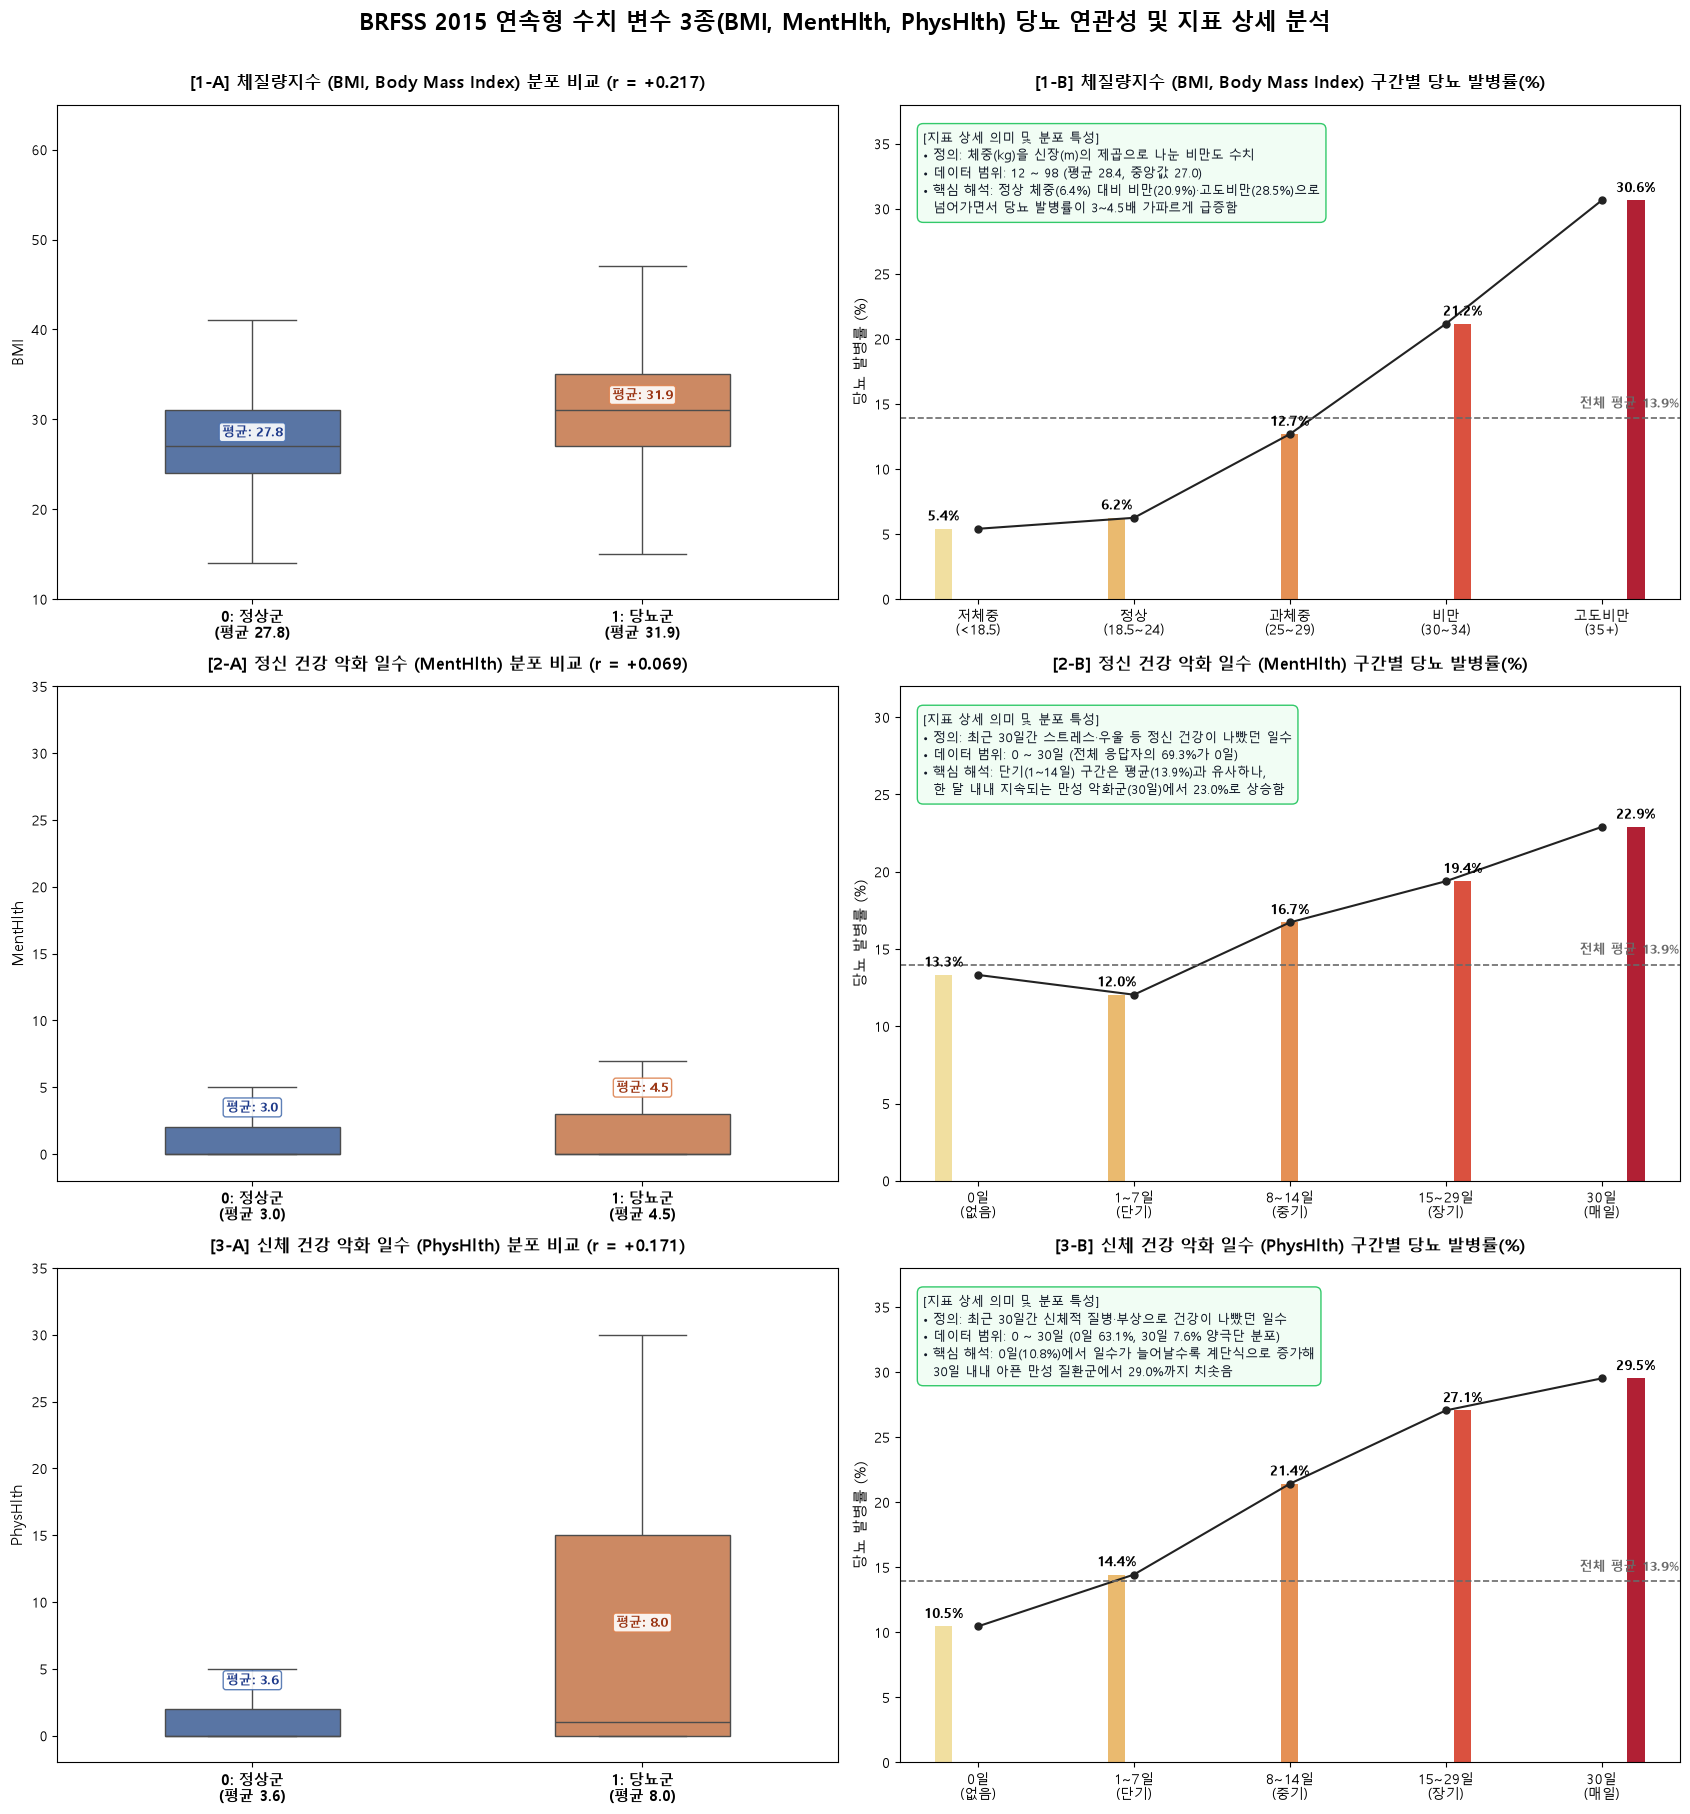

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. 한글 폰트 및 마이너스 기호 깨짐 방지 (Windows 기준)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 2. 데이터 로드 (notebooks/ 폴더 기준 상위 경로 지정)
file_path = '../data/raw/diabetes_binary_health_indicators_BRFSS2015.csv'
df = pd.read_csv(file_path)

# 3. 연속형 변수 3종의 상세 의미 및 구간화 기준 정의
continuous_info = {
    'BMI': {
        'title': '체질량지수 (BMI, Body Mass Index)',
        'bins': [0, 18.5, 25, 30, 35, 100],
        'labels': ['저체중\n(<18.5)', '정상\n(18.5~24)', '과체중\n(25~29)', '비만\n(30~34)', '고도비만\n(35+)'],
        'box_ylim': (10, 65),
        'bar_ylim': (0, 38),
        'desc_box': (
            "[지표 상세 의미 및 분포 특성]\n"
            "• 정의: 체중(kg)을 신장(m)의 제곱으로 나눈 비만도 수치\n"
            "• 데이터 범위: 12 ~ 98 (평균 28.4, 중앙값 27.0)\n"
            "• 핵심 해석: 정상 체중(6.4%) 대비 비만(20.9%)·고도비만(28.5%)으로\n"
            "  넘어가면서 당뇨 발병률이 3~4.5배 가파르게 급증함"
        ),
        'box_loc': (0.03, 0.95)
    },
    'MentHlth': {
        'title': '정신 건강 악화 일수 (MentHlth)',
        'bins': [-1, 0, 7, 14, 29, 30],
        'labels': ['0일\n(없음)', '1~7일\n(단기)', '8~14일\n(중기)', '15~29일\n(장기)', '30일\n(매일)'],
        'box_ylim': (-2, 35),
        'bar_ylim': (0, 32),
        'desc_box': (
            "[지표 상세 의미 및 분포 특성]\n"
            "• 정의: 최근 30일간 스트레스·우울 등 정신 건강이 나빴던 일수\n"
            "• 데이터 범위: 0 ~ 30일 (전체 응답자의 69.3%가 0일)\n"
            "• 핵심 해석: 단기(1~14일) 구간은 평균(13.9%)과 유사하나,\n"
            "  한 달 내내 지속되는 만성 악화군(30일)에서 23.0%로 상승함"
        ),
        'box_loc': (0.03, 0.95)
    },
    'PhysHlth': {
        'title': '신체 건강 악화 일수 (PhysHlth)',
        'bins': [-1, 0, 7, 14, 29, 30],
        'labels': ['0일\n(없음)', '1~7일\n(단기)', '8~14일\n(중기)', '15~29일\n(장기)', '30일\n(매일)'],
        'box_ylim': (-2, 35),
        'bar_ylim': (0, 38),
        'desc_box': (
            "[지표 상세 의미 및 분포 특성]\n"
            "• 정의: 최근 30일간 신체적 질병·부상으로 건강이 나빴던 일수\n"
            "• 데이터 범위: 0 ~ 30일 (0일 63.1%, 30일 7.6% 양극단 분포)\n"
            "• 핵심 해석: 0일(10.8%)에서 일수가 늘어날수록 계단식으로 증가해\n"
            "  30일 내내 아픈 만성 질환군에서 29.0%까지 치솟음"
        ),
        'box_loc': (0.03, 0.95)
    }
}

# 4. 3행 2열 서브플롯 시각화
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(17, 18))
overall_rate = df['Diabetes_binary'].mean() * 100

for idx, (col, info) in enumerate(continuous_info.items()):
    ax_box = axes[idx, 0]  # 왼쪽: 정상 vs 당뇨 분포 비교 (Boxplot)
    ax_bar = axes[idx, 1]  # 오른쪽: 구간별 당뇨 발병률 추이 + 지표 설명 박스
    
    corr = df[col].corr(df['Diabetes_binary'])
    mean_0 = df[df['Diabetes_binary'] == 0][col].mean()
    mean_1 = df[df['Diabetes_binary'] == 1][col].mean()
    
    # [왼쪽 차트] 당뇨 여부에 따른 수치 분포 비교 (Boxplot)
    sns.boxplot(
        data=df,
        x='Diabetes_binary',
        y=col,
        hue='Diabetes_binary',
        palette=['#4C72B0', '#DD8452'],
        legend=False,
        ax=ax_box,
        width=0.45,
        showfliers=False  # 극단 이상치 점 숨김으로 사분위수 상자 가독성 확보
    )
    ax_box.set_title(f"[{idx+1}-A] {info['title']} 분포 비교 (r = {corr:+.3f})",
                     fontsize=12.5, fontweight='bold', pad=12)
    ax_box.set_xticks([0, 1])
    ax_box.set_xticklabels([f'0: 정상군\n(평균 {mean_0:.1f})', f'1: 당뇨군\n(평균 {mean_1:.1f})'],
                           fontsize=10.5, fontweight='bold')
    ax_box.set_xlabel('')
    ax_box.set_ylabel(col, fontsize=10.5)
    ax_box.set_ylim(info['box_ylim'])
    
    # 상자 위에 평균값 텍스트 강조 표시
    ax_box.text(0, mean_0, f'평균: {mean_0:.1f}', ha='center', va='bottom',
                fontsize=9.5, fontweight='bold', color='#1E3A8A',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#4C72B0', alpha=0.9))
    ax_box.text(1, mean_1, f'평균: {mean_1:.1f}', ha='center', va='bottom',
                fontsize=9.5, fontweight='bold', color='#9A3412',
                bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='#DD8452', alpha=0.9))
    
    # [오른쪽 차트] 수치 구간별 당뇨 발병률(%) 추이 및 지표 상세 의미 박스
    temp_bin = pd.cut(df[col], bins=info['bins'], labels=info['labels'])
    prob_df = df.groupby(temp_bin, observed=False)['Diabetes_binary'].mean().reset_index()
    prob_df['Diabetes_Rate'] = prob_df['Diabetes_binary'] * 100
    
    sns.barplot(
        data=prob_df,
        x=col,
        y='Diabetes_Rate',
        hue=col,
        palette='YlOrRd',
        legend=False,
        ax=ax_bar,
        width=0.55
    )
    ax_bar.plot(range(len(prob_df)), prob_df['Diabetes_Rate'],
                color='#222222', marker='o', markersize=5, linewidth=1.5)
    
    # 전체 평균 기준선
    ax_bar.axhline(overall_rate, color='dimgray', linestyle='--', linewidth=1.2)
    ax_bar.text(len(prob_df) - 0.5, overall_rate + 0.6, f'전체 평균 {overall_rate:.1f}%',
                ha='right', va='bottom', fontsize=9, color='dimgray', fontweight='bold')
    
    # 지표 상세 설명 박스 삽입
    ax_bar.text(info['box_loc'][0], info['box_loc'][1], info['desc_box'],
                transform=ax_bar.transAxes, ha='left', va='top', fontsize=9.3,
                color='#111827', linespacing=1.35,
                bbox=dict(boxstyle='round,pad=0.45', facecolor='#F0FDF4', edgecolor='#22C55E', alpha=0.92))
    
    ax_bar.set_title(f"[{idx+1}-B] {info['title']} 구간별 당뇨 발병률(%)",
                     fontsize=12.5, fontweight='bold', pad=12)
    ax_bar.set_xlabel('')
    ax_bar.set_ylabel('당뇨 발병률 (%)', fontsize=10.5)
    ax_bar.set_ylim(info['bar_ylim'])
    ax_bar.tick_params(axis='x', labelsize=9.8)
    
    for p in ax_bar.patches:
        h = p.get_height()
        ax_bar.annotate(
            f'{h:.1f}%',
            (p.get_x() + p.get_width() / 2., h),
            ha='center', va='bottom',
            fontsize=10, fontweight='bold',
            xytext=(0, 4), textcoords='offset points'
        )

plt.suptitle('BRFSS 2015 연속형 수치 변수 3종(BMI, MentHlth, PhysHlth) 당뇨 연관성 및 지표 상세 분석',
             fontsize=16.5, fontweight='bold', y=1.005)
plt.tight_layout()

# 필요시 이미지 저장 (주석 해제 후 사용)
# plt.savefig('../reports/figures/continuous_3_features_diabetes_relation.png', dpi=300, bbox_inches='tight')
plt.show()

## [연속추치 3개 지표의 경우] 차트해석과 인사이트 도출

1. 변수별 핵심 해석 및 분포 패턴

① 체질량지수 (BMI, Body Mass Index) | 상관계수 $r = +0.217$   그룹 간 분포 격차: 당뇨군 평균(31.9, 비만 영역)이 정상군 평균(27.8, 과체중 영역)보다 약 4.1 높으며, 사분위수 상자 전체가 위쪽으로 뚜렷하게 이동해 있음.   구간별 발병률 추이: 저체중(<18.5) 5.4% → 정상(18.5~24) 6.2% → 과체중(25~29) 12.7% → 비만(30~34) 21.2% → 고도비만(35+) 30.6%   핵심 해석: 비만 기준점(BMI 30)을 넘어서는 순간 전체 평균 유병률(13.9%)을 크게 돌파하며, 정상 체중 대비 당뇨 발병률이 약 3.4배(비만) ~ 4.9배(고도비만)까지 폭발적으로 급증하는 가장 강력한 연속형 예측 인자임.   

② 정신 건강 악화 일수 (MentHlth, 최근 30일 기준) | 상관계수 $r = +0.069$   그룹 간 분포 격차: 당뇨군 평균(4.5일)이 정상군(3.0일)보다 높으나, 전체 응답자의 약 69.3%가 0일에 몰려 있어 중앙값은 양쪽 모두 0일로 나타남.   구간별 발병률 추이: 0일 13.3% → 1~7일 12.0% → 8~14일 16.7% → 15~29일 19.4% → 30일(매일) 22.9%   핵심 해석: 단기적인 스트레스(1~7일)는 당뇨와 유의미한 연관성이 없으나, 2주 이상 지속되거나 한 달 내내(30일) 정신 건강 악화를 겪는 만성 집단에서는 발병률이 22.9%까지 상승하는 임계점 특성을 보임.   

③ 신체 건강 악화 일수 (PhysHlth, 최근 30일 기준) | 상관계수 $r = +0.171$   그룹 간 분포 격차: 당뇨군 평균(8.0일)이 정상군 평균(3.6일)의 2.2배 이상이며, 당뇨군의 상위 75% 경계선(Q3)이 15일 수준까지 크게 확장되어 있음.   구간별 발병률 추이: 0일 10.5% → 1~7일 14.4% → 8~14일 21.4% → 15~29일 27.1% → 30일(매일) 29.5%   핵심 해석: 건강 악화 일수가 1일이라도 발생하면 평균(13.9%)을 넘어서며, 일수가 늘어날수록 당뇨 유병률이 계단식으로 가파르게 상승해 만성 신체 질환군(30일)에서는 약 3명 중 1명(29.5%)이 당뇨를 동반함.  

 2. 머신러닝 모델링 및 피처 엔지니어링 인사이트
 
 비선형 임계점 기반 범주화(Binning) 필수:BMI는 30 이상(비만)에서 기울기가 급변하므로 Is_Obese(BMI >= 30) 이진 플래그 또는 WHO 5단계 구간화 변수를 추가하면 모델의 분기 정확도가 높아짐.MentHlth와 PhysHlth는 0일에 극단적으로 쏠린 Zero-inflated 분포이므로, 원본 연속형 값 외에 만성 악화 플래그(15일 이상 또는 30일)로 범주화해 투입하면 선형 모델의 예측 왜곡을 줄일 수 있음.
 
 단위 차이 보정을 위한 스케일링(Scaling) 적용:BMI(12~98)와 악화 일수(0~30), 그리고 다른 0/1 이진 변수 간의 숫자 크기 격차가 크므로, 로지스틱 회귀 등 거리·가중치 기반 모델 학습 전 Train 데이터 기준 StandardScaler 또는 MinMaxScaler 적용이 필수적임.   
 
 다중공선성 주의 (PhysHlth vs GenHlth):PhysHlth는 당뇨 예측력이 우수하지만($r = +0.171$), 앞서 확인한 주관적 건강 상태(GenHlth)와 상관도가 매우 높으므로($r = 0.52$) 선형 모델에서는 규제(Ridge/Lasso)를 함께 적용해 가중치 분산을 통제해야 함.

 (참고)적 '일수(객관적 빈도)' vs 종합적 '등급(주관적 체감)'
PhysHlth는 최근 한 달(30일)이라는 제한된 기간 동안 실제로 몸이 아팠던 날짜 수를 센 지표(정량적)
반면 GenHlth는 특정 기간에 얽매이지 않고 본인이 평소 느끼는 전체적인 건강 수준을 5단계 점수로 매긴 자기 평가(Self-rated Health) 지표(주관척도)


In [11]:
# 전체 22개 지표 결측치 합계 확인 (결과가 0이면 결측치 없음)
print("전체 결측치 수:", df.isnull().sum().sum())

전체 결측치 수: 0


In [12]:
import os
import pandas as pd

# 1. 가장 최근에 보정하여 저장한 CSV 파일 로드
# (Education 1·2등급 병합 + Age 서열 유지 + Stroke/HeartDisease 결합 완료본)
input_path = '../data/processed/diabetes_binary_edu_merged_age_ordinal_cardio_combined.csv'
df = pd.read_csv(input_path)
print(f"📌 최근 보정 데이터 로드 완료: {df.shape[0]:,}행 × {df.shape[1]}열")

# ==============================================================================
# 2. 연속형 수치 변수 3종 범주화(Binning) 적용
# ==============================================================================

# ① BMI -> WHO 기준 5단계 범주화 (BMI_Group)
# 구간: 저체중(<18.5) / 정상(18.5~24.9) / 과체중(25.0~29.9) / 비만(30.0~34.9) / 고도비만(35.0+)
bmi_bins = [0, 18.5, 25.0, 30.0, 35.0, 100.0]
bmi_labels = ['Underweight', 'Normal', 'Overweight', 'Obese', 'Severely_Obese']
df['BMI_Group'] = pd.cut(df['BMI'], bins=bmi_bins, labels=bmi_labels, right=False)

# ② MentHlth & PhysHlth -> 3단계 범주화 (MentHlth_Group, PhysHlth_Group)
# 구간: 0일(None) / 1~14일(Moderate) / 15~30일(Severe)
health_bins = [-1, 0, 14, 30]
health_labels = ['None (0 days)', 'Moderate (1-14 days)', 'Severe (15-30 days)']
df['MentHlth_Group'] = pd.cut(df['MentHlth'], bins=health_bins, labels=health_labels, right=True)
df['PhysHlth_Group'] = pd.cut(df['PhysHlth'], bins=health_bins, labels=health_labels, right=True)

# ==============================================================================
# 3. 추가된 3개 범주화 컬럼 분포 및 결측치 검증
# ==============================================================================
print("\n=== [검증 1] BMI_Group (WHO 5단계) 분포 ===")
print(df['BMI_Group'].value_counts(dropna=False))

print("\n=== [검증 2] MentHlth_Group (3단계) 분포 ===")
print(df['MentHlth_Group'].value_counts(dropna=False))

print("\n=== [검증 3] PhysHlth_Group (3단계) 분포 ===")
print(df['PhysHlth_Group'].value_counts(dropna=False))

# 범주화 경계 누락으로 인한 결측치가 없는지 최종 확인
assert df[['BMI_Group', 'MentHlth_Group', 'PhysHlth_Group']].isnull().sum().sum() == 0, "경계값 누락 확인 필요!"

# ==============================================================================
# 4. data/processed 폴더에 최종 통합 파일명으로 저장
# ==============================================================================
output_dir = '../data/processed'
os.makedirs(output_dir, exist_ok=True)

# 기존 처리 내역 + 연속형 3종(BMI 5단계, 건강악화일수 3단계) 범주화 통합 파일명
output_filename = 'diabetes_binary_edu_cardio_bmi5_health3_binned.csv'
output_path = os.path.join(output_dir, output_filename)

df.to_csv(output_path, index=False)

print(f"\n💾 저장 완료! 총 컬럼 수: {df.shape[1]}개 (기존 21개 → 24개)")
print(f"📁 저장 위치: {output_path}")

📌 최근 보정 데이터 로드 완료: 253,680행 × 21열

=== [검증 1] BMI_Group (WHO 5단계) 분포 ===
BMI_Group
Overweight        93749
Normal            68953
Obese             53451
Severely_Obese    34400
Underweight        3127
Name: count, dtype: int64

=== [검증 2] MentHlth_Group (3단계) 분포 ===
MentHlth_Group
None (0 days)           175680
Moderate (1-14 days)     54630
Severe (15-30 days)      23370
Name: count, dtype: int64

=== [검증 3] PhysHlth_Group (3단계) 분포 ===
PhysHlth_Group
None (0 days)           160052
Moderate (1-14 days)     62555
Severe (15-30 days)      31073
Name: count, dtype: int64

💾 저장 완료! 총 컬럼 수: 24개 (기존 21개 → 24개)
📁 저장 위치: ../data/processed\diabetes_binary_edu_cardio_bmi5_health3_binned.csv


## [연속형 변수 3종]범주화(Binning)  결정 요약

① BMI (체질량지수) $\rightarrow$ WHO 기준 5단계 범주화 (BMI_Group)
구간 기준: 저체중(<18.5) / 정상(18.5~24.9) / 과체중(25.0~29.9) / 비만(30.0~34.9) / 고도비만(35.0+)
결정 근거: 비만 경계선(BMI 30) 초과 시 당뇨 발병률이 가파르게 급등하는(과체중 12.7% $\rightarrow$ 비만 21.2% $\rightarrow$ 고도비만 30.6%) 의학적 임계점 및 비선형 위험도를 모델에 명확히 반영하기 위함

② MentHlth & PhysHlth (건강 악화 일수) $\rightarrow$ 3단계 범주화 (MentHlth_Group, PhysHlth_Group)
구간 기준: 0일(None: 없음) / 1~14일(Moderate: 단기·간헐) / 15~30일(Severe: 만성·장기)
결정 근거: 전체 응답자의 63~69%가 0일에 몰린 0-과잉(Zero-inflated) 편향 분포를 보정하고, 비악화군(0일)과 한 달 내내 지속되는 만성 악화군(15~30일) 간의 뚜렷한 유병률 격차를 구분해 학습시키기 위함

## : 누적 반영된 전처리 항목 (총 24개 컬럼):

Education: 1·2등급 병합된 5단계 서열(1~5) 유지

Age: 원본 13단계 서열(1~13) 유지

CardioDisease: 뇌졸중(Stroke) + 심장질환(HeartDiseaseorAttack) 통합 이진 변수

BMI_Group (신규): WHO 5단계(Underweight, Normal, Overweight, Obese, Severely_Obese) — right=False 옵션을 적용해 BMI 18.5, 25.0, 30.0, 35.0 경계값이 의학적 기준과 정확히 일치하도록 처리했습니다.

MentHlth_Group, PhysHlth_Group (신규): 3단계(None (0 days), Moderate (1-14 days), Severe (15-30 days)) 추가 (기존 연속형 원본 컬럼 3개도 모델 비교를 위해 함께 보존됩니다).

##  지표별 이상치(Outlier) 처리 대상 여부 및 근거 요약

* **연속형(측정치) — `BMI` (체질량지수): 필수 처리 (극단값 제거 또는 상한 고정)**
  * 최솟값 `12` ~ 최댓값 `98` 중 `60 이상(60~98)`에 해당하는 초고도비만·입력 오류 극단값(약 0.2%)이 포함되어 있음.
  * 소수의 극단값이 선형 모델의 회귀선 기울기와 스케일링(`StandardScaler`/`MinMaxScaler`) 범위를 크게 왜곡하므로 도메인 기준 범위 규칙(`between 12, 60`)을 적용해 제어해야 함.

* **연속형(일수) — `MentHlth`, `PhysHlth` (건강 악화 일수): 제거 불필요 (구간화로 대체)**
  * 최근 30일이라는 물리적 상한(`0 ~ 30일`)이 명확히 존재해 데이터 오류값이 없음.
  * `0일`(63~69%)과 `30일`(4.8~7.6%) 양 끝에 분포가 쏠려 있으므로 값을 삭제하는 대신 **3단계 범주화(`0일`, `1~14일`, `15~30일`)** 또는 `RobustScaler`로 분포 편향을 보정함.

* **등급형(서열) — `GenHlth`, `Age`, `Education`, `Income`: 제거 불필요 (희소 등급 병합으로 대체)**
  * 정해진 코드북 범위(`1~5`, `1~13` 등) 내의 유효한 설문 응답이므로 수치적 이상치가 아님.
  * 표본이 극소수인 구간(`Education` 1등급 0.07%)은 삭제하지 않고 인접 등급(`2등급`)과 병합하여 표본 안정성을 확보함.

* **이진형(0/1) — `HighBP` 외 14종: 제거 불필요**
  * 모든 값이 `0`과 `1`로만 구성된 범주형 지표이므로 이상치 개념이 적용되지 않음.

### 🛠️ `BMI` 이상치 구체적 처리 기준 및 방법 요약

* **적정 이상치 기준선 설정: `BMI 60 이상` (또는 `12 미만 ~ 60 초과`)**
  * **도메인 근거:** 의학적 초고도비만(Class 3 Obesity) 기준이 `BMI 40 이상`이므로, `BMI 60 이상`(예: 키 170cm 기준 체중 175kg 이상)은 현실에서 극히 드물거나 전화 설문 응답자의 입력 오류일 가능성이 높음.
  * **표본 손실 최소화:** 전체 253,680건 중 `BMI >= 60` 데이터는 약 584건(약 0.23%)에 불과해 처리해도 데이터 손실이 거의 없음
  * **IQR 방식 배제:** 통계적 IQR 기준을 기계적으로 적용하면 당뇨 발병률이 가장 높은 핵심 예측 구간(`BMI 41~55` 고도비만군)까지 이상치로 잘려나가므로 도메인 기준(`10 < BMI < 60`)을 적용함

* **구체적 처리 방법 선택**
  * ** 상하한 고정해 데이터를 살리기보다는 제거하기 (Drop)로 결정.
    * `df[(df['BMI'] > 10) & (df['BMI'] < 60)]` 조건으로 극단치 행을 삭제하여 모델 학습 및 스케일링 왜곡을 원천 차단함



In [13]:
import os
import pandas as pd

# 1. 가장 최근에 저장한 전처리·범주화 통합 CSV 파일 로드
input_path = '../data/processed/diabetes_binary_edu_cardio_bmi5_health3_binned.csv'
df = pd.read_csv(input_path)
print(f"📌 최근 보정 데이터 로드 완료: {df.shape[0]:,}행 × {df.shape[1]}열")

# ==============================================================================
# 2. BMI 이상치 제거 (도메인 기준: 10 초과 ~ 60 미만 유지)
# ==============================================================================
initial_rows = len(df)
df_cleaned = df[(df['BMI'] > 10) & (df['BMI'] < 60)].copy()
removed_rows = initial_rows - len(df_cleaned)

print(f"🗑️ 제거된 BMI 이상치 행 수 (BMI <= 10 또는 >= 60): {removed_rows:,}개 ({removed_rows/initial_rows*100:.2f}%)")
print(f"✨ 이상치 제거 후 최종 데이터 행 수: {len(df_cleaned):,}개")

# ==============================================================================
# 3. 이상치 제거 후 BMI_Group(WHO 5단계) 재정돈 및 최종 검증
# ==============================================================================
bmi_bins = [0, 18.5, 25.0, 30.0, 35.0, 60.0]
bmi_labels = ['Underweight', 'Normal', 'Overweight', 'Obese', 'Severely_Obese']
df_cleaned['BMI_Group'] = pd.cut(df_cleaned['BMI'], bins=bmi_bins, labels=bmi_labels, right=False)

print("\n=== [검증 1] 이상치 제거 후 BMI 수치 범위 ===")
print(f"최솟값(min): {df_cleaned['BMI'].min()} | 최댓값(max): {df_cleaned['BMI'].max()}")

print("\n=== [검증 2] 최종 BMI_Group (WHO 5단계) 분포 ===")
print(df_cleaned['BMI_Group'].value_counts(dropna=False))

# 결측치 최종 확인
assert df_cleaned.isnull().sum().sum() == 0, "결측치가 존재합니다!"

# ==============================================================================
# 4. data/processed 폴더에 보정 내역이 반영된 파일명으로 저장
# ==============================================================================
output_dir = '../data/processed'
os.makedirs(output_dir, exist_ok=True)

# 파일명 요약: Education병합 + 심혈관결합 + BMI이상치제거(bmi_outlier_removed) + BMI5단계/건강3단계범주화
output_filename = 'diabetes_binary_edu_cardio_bmi_outlier_removed_binned.csv'
output_path = os.path.join(output_dir, output_filename)

df_cleaned.to_csv(output_path, index=False)

print(f"\n💾 최종 정제 데이터 저장 완료! ({df_cleaned.shape[0]:,}행 × {df_cleaned.shape[1]}열)")
print(f"📁 저장 위치: {output_path}")

📌 최근 보정 데이터 로드 완료: 253,680행 × 24열
🗑️ 제거된 BMI 이상치 행 수 (BMI <= 10 또는 >= 60): 868개 (0.34%)
✨ 이상치 제거 후 최종 데이터 행 수: 252,812개

=== [검증 1] 이상치 제거 후 BMI 수치 범위 ===
최솟값(min): 12.0 | 최댓값(max): 59.0

=== [검증 2] 최종 BMI_Group (WHO 5단계) 분포 ===
BMI_Group
Overweight        93749
Normal            68953
Obese             53451
Severely_Obese    33532
Underweight        3127
Name: count, dtype: int64

💾 최종 정제 데이터 저장 완료! (252,812행 × 24열)
📁 저장 위치: ../data/processed\diabetes_binary_edu_cardio_bmi_outlier_removed_binned.csv


In [16]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

output_dir = '../data/interim/Part2EDA2'
os.makedirs(output_dir, exist_ok=True)

df = pd.read_csv('../data/raw/diabetes_binary_health_indicators_BRFSS2015.csv')
overall_rate = df['Diabetes_binary'].mean() * 100

ordinal_info = {
    'GenHlth': {
        'title': '일반 건강 상태 (GenHlth, 1~5등급)',
        'corr_desc': '양의 상관 (+): 숫자가 클수록 당뇨 발병률 급증',
        'xticks': ['1\n최상', '2\n매우좋음', '3\n좋음', '4\n보통', '5\n나쁨'],
        'legend_text': "[등급 기준]\n1:최상 2:매우좋음 3:좋음\n4:보통 5:나쁨",
        'box_loc': (0.03, 0.95), 'ylim': 42
    },
    'Age': {
        'title': '연령대 구분 (Age, 1~13등급)',
        'corr_desc': '양의 상관 (+): 70대 초반까지 유병률 꾸준히 상승',
        'xticks': ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13'],
        'legend_text': "[연령 기준 (5세 단위)]\n1:18~24세 ~ 11:70~74세\n12:75~79세, 13:80세+",
        'box_loc': (0.03, 0.95), 'ylim': 30
    },
    'Education': {
        'title': '최종 학력 수준 (Education, 1~6등급)',
        'corr_desc': '음의 상관 (-): 고학력일수록 당뇨 발병률 감소',
        'xticks': ['1\n무학', '2\n초졸', '3\n고교중퇴', '4\n고졸', '5\n전문/재학', '6\n대졸+'],
        'legend_text': "[학력 기준]\n1:무학 2:초졸 3:고교중퇴\n4:고졸 5:전문대 6:대졸+",
        'box_loc': (0.55, 0.95), 'ylim': 35
    },
    'Income': {
        'title': '연간 가구 소득 (Income, 1~8등급)',
        'corr_desc': '음의 상관 (-): 고소득일수록 당뇨 발병률 하락',
        'xticks': ['1', '2', '3', '4', '5', '6', '7', '8'],
        'legend_text': "[소득 기준]\n1:<$1만 ~ 5:<$3.5만\n6:<$5만 ~ 8:$7.5만+",
        'box_loc': (0.55, 0.95), 'ylim': 32
    }
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
axes = axes.flatten()

for idx, (col, info) in enumerate(ordinal_info.items()):
    ax = axes[idx]
    prob_df = df.groupby(col)['Diabetes_binary'].mean().reset_index()
    prob_df['Rate'] = prob_df['Diabetes_binary'] * 100
    corr = df[col].corr(df['Diabetes_binary'])
    palette = 'Reds' if corr > 0 else 'Blues_r'
    
    sns.barplot(data=prob_df, x=col, y='Rate', hue=col, palette=palette, legend=False, ax=ax, width=0.6)
    ax.plot(range(len(prob_df)), prob_df['Rate'], color='#222222', marker='o', linewidth=1.5)
    ax.axhline(overall_rate, color='dimgray', linestyle='--')
    ax.set_title(f"{info['title']} (r = {corr:+.3f})", fontsize=13, fontweight='bold', pad=18)
    ax.text(info['box_loc'][0], info['box_loc'][1], info['legend_text'], transform=ax.transAxes,
            ha='left', va='top', fontsize=9.5, bbox=dict(boxstyle='round', facecolor='#FFFBEB', edgecolor='#F59E0B'))
    ax.set_xticks(range(len(info['xticks'])))
    ax.set_xticklabels(info['xticks'], fontsize=9.5, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('당뇨 발병률 (%)')
    ax.set_ylim(0, info['ylim'])
    
    for p in ax.patches:
        h = p.get_height()
        ax.annotate(f'{h:.1f}%', (p.get_x() + p.get_width() / 2., h),
                    ha='center', va='bottom', fontsize=9, fontweight='bold', xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
save_path_2 = os.path.join(output_dir, '02_ordinal_4_features_diabetes_relation.png')
fig.savefig(save_path_2, dpi=300, bbox_inches='tight')
plt.close(fig)
print("2단계 저장 완료:", save_path_2)

Font 'rm' does not have a glyph for '\ub9cc' [U+b9cc], substituting with a dummy symbol.
Font 'rm' does not have a glyph for '\ub9cc' [U+b9cc], substituting with a dummy symbol.
Font 'rm' does not have a glyph for '\ub9cc' [U+b9cc], substituting with a dummy symbol.
Font 'rm' does not have a glyph for '\ub9cc' [U+b9cc], substituting with a dummy symbol.
Font 'rm' does not have a glyph for '\ub9cc' [U+b9cc], substituting with a dummy symbol.
Font 'rm' does not have a glyph for '\ub9cc' [U+b9cc], substituting with a dummy symbol.


2단계 저장 완료: ../data/interim/Part2EDA2\02_ordinal_4_features_diabetes_relation.png


In [17]:
continuous_info = {
    'BMI': {
        'title': '체질량지수 (BMI)',
        'bins': [0, 18.5, 25, 30, 35, 100],
        'labels': ['저체중', '정상', '과체중', '비만', '고도비만'],
        'box_ylim': (10, 65), 'bar_ylim': (0, 38),
        'desc': "[BMI 의미]\n• 체중(kg)/신장(m)²\n• 비만(30+) 시 발병률 3배 급증"
    },
    'MentHlth': {
        'title': '정신 건강 악화 일수 (MentHlth)',
        'bins': [-1, 0, 7, 14, 29, 30],
        'labels': ['0일', '1~7일', '8~14일', '15~29일', '30일'],
        'box_ylim': (-2, 35), 'bar_ylim': (0, 32),
        'desc': "[MentHlth 의미]\n• 최근 30일 정신 악화 일수\n• 30일 만성군 22.9% 상승"
    },
    'PhysHlth': {
        'title': '신체 건강 악화 일수 (PhysHlth)',
        'bins': [-1, 0, 7, 14, 29, 30],
        'labels': ['0일', '1~7일', '8~14일', '15~29일', '30일'],
        'box_ylim': (-2, 35), 'bar_ylim': (0, 38),
        'desc': "[PhysHlth 의미]\n• 최근 30일 신체 악화 일수\n• 일수 비례해 29.5%까지 상승"
    }
}

fig2, axes2 = plt.subplots(3, 2, figsize=(15, 16))

for idx, (col, info) in enumerate(continuous_info.items()):
    ax_box, ax_bar = axes2[idx, 0], axes2[idx, 1]
    corr = df[col].corr(df['Diabetes_binary'])
    m0 = df[df['Diabetes_binary'] == 0][col].mean()
    m1 = df[df['Diabetes_binary'] == 1][col].mean()
    
    sns.boxplot(data=df, x='Diabetes_binary', y=col, hue='Diabetes_binary',
                palette=['#4C72B0', '#DD8452'], legend=False, ax=ax_box, width=0.45, showfliers=False)
    ax_box.set_title(f"{info['title']} 분포 (r = {corr:+.3f})", fontsize=12, fontweight='bold')
    ax_box.set_xticks([0, 1])
    ax_box.set_xticklabels([f'정상 (평균 {m0:.1f})', f'당뇨 (평균 {m1:.1f})'], fontweight='bold')
    ax_box.set_xlabel('')
    ax_box.set_ylim(info['box_ylim'])
    
    temp_bin = pd.cut(df[col], bins=info['bins'], labels=info['labels'])
    prob_df = df.groupby(temp_bin, observed=False)['Diabetes_binary'].mean().reset_index()
    prob_df['Rate'] = prob_df['Diabetes_binary'] * 100
    
    sns.barplot(data=prob_df, x=col, y='Rate', hue=col, palette='YlOrRd', legend=False, ax=ax_bar, width=0.55)
    ax_bar.plot(range(len(prob_df)), prob_df['Rate'], color='#222222', marker='o', linewidth=1.5)
    ax_bar.axhline(overall_rate, color='dimgray', linestyle='--')
    ax_bar.text(0.03, 0.95, info['desc'], transform=ax_bar.transAxes, ha='left', va='top',
                fontsize=9.5, bbox=dict(boxstyle='round', facecolor='#F0FDF4', edgecolor='#22C55E'))
    ax_bar.set_title(f"{info['title']} 구간별 발병률(%)", fontsize=12, fontweight='bold')
    ax_bar.set_xlabel('')
    ax_bar.set_ylabel('당뇨 발병률 (%)')
    ax_bar.set_ylim(info['bar_ylim'])
    
    for p in ax_bar.patches:
        h = p.get_height()
        ax_bar.annotate(f'{h:.1f}%', (p.get_x() + p.get_width() / 2., h),
                        ha='center', va='bottom', fontsize=9.5, fontweight='bold', xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
save_path_3 = os.path.join(output_dir, '03_continuous_3_features_diabetes_relation.png')
fig2.savefig(save_path_3, dpi=300, bbox_inches='tight')
plt.close(fig2)
print("3단계 저장 완료:", save_path_3)
print("폴더 내 전체 파일:", sorted(os.listdir(output_dir)))

3단계 저장 완료: ../data/interim/Part2EDA2\03_continuous_3_features_diabetes_relation.png
폴더 내 전체 파일: ['02_ordinal_4_features_diabetes_relation.png', '03_continuous_3_features_diabetes_relation.png']


In [18]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

output_dir = '../data/interim/Part2EDA2'
os.makedirs(output_dir, exist_ok=True)

df = pd.read_csv('../data/raw/diabetes_binary_health_indicators_BRFSS2015.csv')
overall_rate = df['Diabetes_binary'].mean() * 100

binary_labels_kr = {
    'HighBP': '고혈압 (HighBP)',
    'HighChol': '고콜레스테롤 (HighChol)',
    'CholCheck': '5년내 콜레스테롤검사 (CholCheck)',
    'Smoker': '흡연 경험 (Smoker)',
    'Stroke': '뇌졸중 병력 (Stroke)',
    'HeartDiseaseorAttack': '심장질환/심근경색 (HeartDisease)',
    'PhysActivity': '신체활동 여부 (PhysActivity)',
    'Fruits': '과일 섭취 (Fruits)',
    'Veggies': '채소 섭취 (Veggies)',
    'HvyAlcoholConsump': '과음 여부 (HvyAlcohol)',
    'AnyHealthcare': '의료보험 가입 (AnyHealthcare)',
    'NoDocbcCost': '비용문제 병원미방문 (NoDocbcCost)',
    'DiffWalk': '보행/계단 어려움 (DiffWalk)',
    'Sex': '성별 (0:여성, 1:남성)'
}

records = []
for col, label in binary_labels_kr.items():
    r0 = df[df[col] == 0]['Diabetes_binary'].mean() * 100
    r1 = df[df[col] == 1]['Diabetes_binary'].mean() * 100
    corr = df[col].corr(df['Diabetes_binary'])
    records.append({'Feature': f"{label}\n(r = {corr:+.3f})", 'Rate_0': r0, 'Rate_1': r1})

bin_df = pd.DataFrame(records).sort_values(by='Rate_1', ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(15, 9))
y_pos = range(len(bin_df))
h = 0.38

b1 = ax.barh([y - h/2 for y in y_pos], bin_df['Rate_1'], height=h, label='1 (예 / 해당함 / 남성)', color='#DC2626', alpha=0.88)
b0 = ax.barh([y + h/2 for y in y_pos], bin_df['Rate_0'], height=h, label='0 (아니오 / 해당없음 / 여성)', color='#3B82F6', alpha=0.82)

ax.axvline(overall_rate, color='dimgray', linestyle='--', linewidth=1.3)
ax.text(overall_rate + 0.4, len(bin_df) - 0.3, f'전체 평균 {overall_rate:.1f}%', color='dimgray', fontsize=10, fontweight='bold')

ax.set_yticks(y_pos)
ax.set_yticklabels(bin_df['Feature'], fontsize=10, fontweight='bold')
ax.invert_yaxis()
ax.set_xlabel('당뇨 발병률 (%)', fontsize=11.5, fontweight='bold')
ax.set_xlim(0, 40)
ax.set_title('[1단계] BRFSS 2015 이진형(Binary) 변수 14종별 당뇨 발병률 비교 (0 vs 1)', fontsize=15, fontweight='bold', pad=15)
ax.legend(loc='lower right', fontsize=11, frameon=True, facecolor='#F8FAFC')

for bar in b1:
    w = bar.get_width()
    ax.text(w + 0.35, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=8.8, fontweight='bold', color='#991B1B')

for bar in b0:
    w = bar.get_width()
    ax.text(w + 0.35, bar.get_y() + bar.get_height()/2, f'{w:.1f}%', va='center', fontsize=8.8, color='#1E40AF')

plt.tight_layout()
save_path_1 = os.path.join(output_dir, '01_binary_14_features_diabetes_relation.png')
fig.savefig(save_path_1, dpi=300, bbox_inches='tight')
plt.close(fig)

print("1단계 저장 완료:", save_path_1)
print("폴더 내 전체 파일:", sorted(os.listdir(output_dir)))

1단계 저장 완료: ../data/interim/Part2EDA2\01_binary_14_features_diabetes_relation.png
폴더 내 전체 파일: ['01_binary_14_features_diabetes_relation.png', '02_ordinal_4_features_diabetes_relation.png', '03_continuous_3_features_diabetes_relation.png']
